# Logistic regression

## Imports


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn.model_selection as model_selection
from sklearn import metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc


## Read In & Understand Data
We will be looking at the Pima Indians Diabetes dataset that can be used to predict whether or not someone has diabetes based on a set of a predictors. Information about this dataset is provided [here](https://www.kaggle.com/uciml/pima-indians-diabetes-database).

In [2]:
url = "http://ddc-datascience.s3.amazonaws.com/pima-indians-diabetes.csv"
url


'http://ddc-datascience.s3.amazonaws.com/pima-indians-diabetes.csv'

In [3]:
!curl -I {url}


HTTP/1.1 200 OK
x-amz-id-2: 2KZ+pKdELk7bibvPFGKXSUPOO2wfrwMoKtj2JxnLhBYyKLjo/oAfFW0S3cjEaNViiq5OfhArh4uMv3/3ku5zCFejiN1bYKaM
x-amz-request-id: 5J69948QECQMZDC9
Server: AmazonS3
Date: Wed, 04 Nov 2026 20:40:21 GMT
Last-Modified: Wed, 02 Aug 2023 23:36:53 GMT
ETag: "519a8917f5461f7d143279ff56411f7e"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 24045
Content-Type: text/csv



Notice ...
- 200 response
- content type of text/csv
- length of about 24kb

In [4]:
!curl -s {url} | head


6,148,72,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
8,183,64,0,0,23.3,0.672,32,1
1,89,66,23,94,28.1,0.167,21,0
0,137,40,35,168,43.1,2.288,33,1
5,116,74,0,0,25.6,0.201,30,0
3,78,50,32,88,31.0,0.248,26,1
10,115,0,0,0,35.3,0.134,29,0
2,197,70,45,543,30.5,0.158,53,1
8,125,96,0,0,0.0,0.232,54,1


Notice ...
- comma separated values
- a mix of floats and ints
- no column headings


## Read in the data



Notice that the data set does not have column names.  So, we will create our own and include them when we create the data frame.


In [5]:
col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']
pima = pd.read_csv(
  url,
  header=None,
  names=col_names,
)
pima


,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [6]:
pima.head()

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [7]:
pima.shape

(768, 9)

In [9]:
pima.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pregnant  768 non-null    int64  
 1   glucose   768 non-null    int64  
 2   bp        768 non-null    int64  
 3   skin      768 non-null    int64  
 4   insulin   768 non-null    int64  
 5   bmi       768 non-null    float64
 6   pedigree  768 non-null    float64
 7   age       768 non-null    int64  
 8   label     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [10]:
pima.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
pregnant,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
bp,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
skin,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
bmi,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
pedigree,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
label,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [11]:
pima['label'].value_counts( dropna = False)


,count
label,
0,500
1,268


In [12]:
X = pima.drop('label',axis=1).copy()
y = pima['label'].copy()

## EDA

### Correlation matrix plot

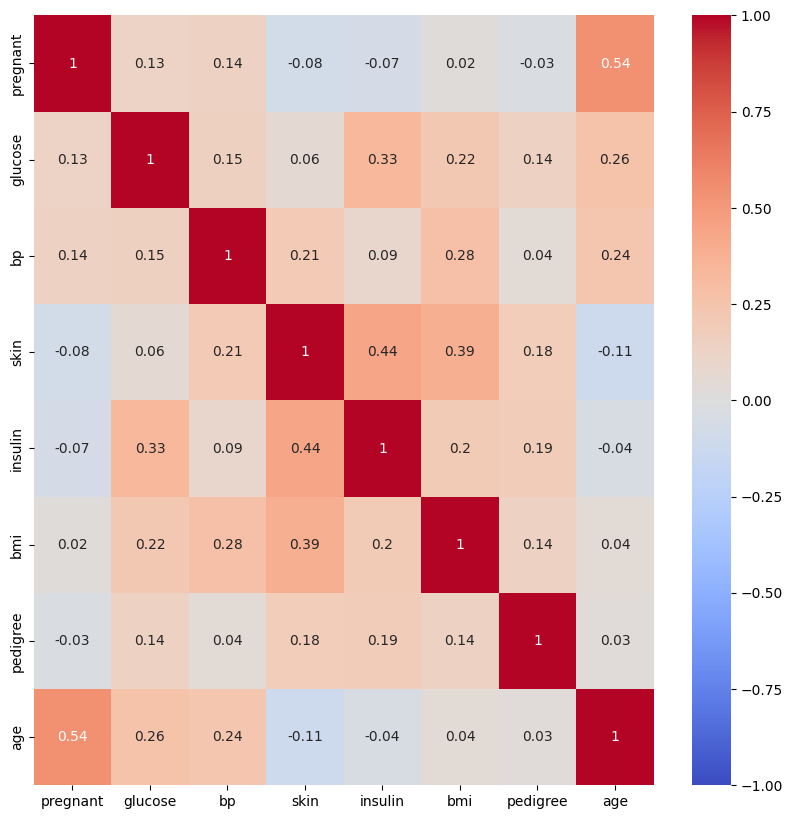

In [13]:
# Checking correlations between predictors
plt.figure(figsize=(10,10))
correlation_matrix = X.corr().round(2)
sns.heatmap(
  data=correlation_matrix,
  cmap='coolwarm',
  annot=True,
  vmin=-1,
  vmax=1
)
plt.show()


### Feature distributions

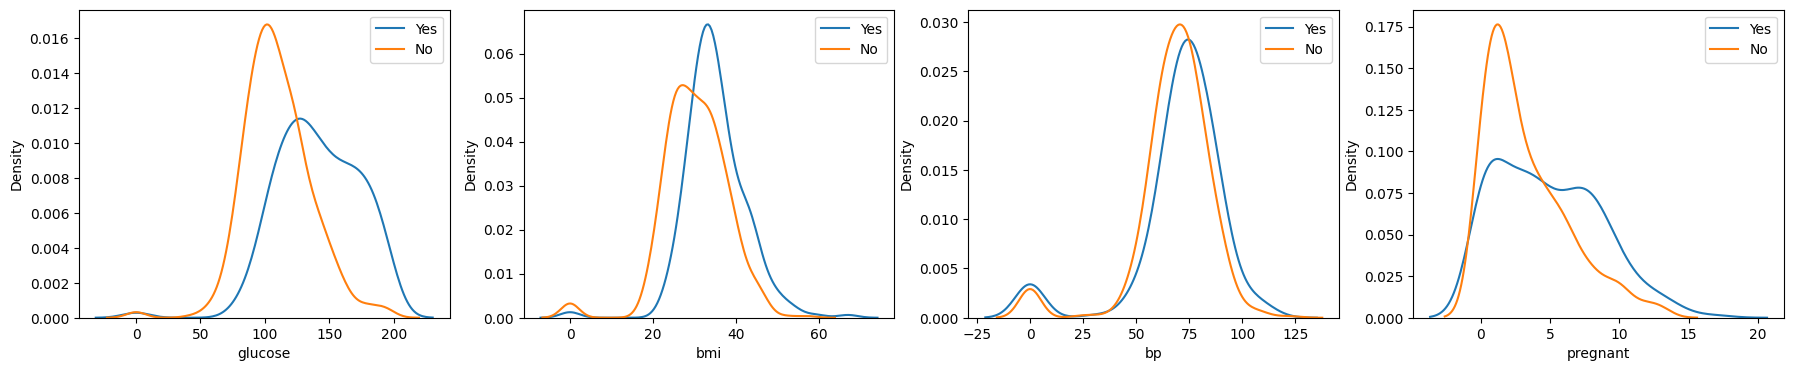

In [14]:
# Look at the distribution of a few predictors for different labels
predictors = ['glucose', 'bmi', 'bp', 'pregnant']

fig, axes = plt.subplots(1,4, figsize= (22,4))
for i,pred in enumerate(predictors):
  sns.kdeplot(pima[pred][y==1], label = 'Yes', ax = axes[i])
  sns.kdeplot(pima[pred][y==0], label = 'No', ax = axes[i])
  axes[i].legend()
plt.show()


## Fit Logistic Model

### Cross validation

In [15]:
numLoops = 50
predict_accuracy = np.zeros(numLoops)
predict_f1 = np.zeros(numLoops)

for idx in range(numLoops):
  # Train/test split
  X_train, X_test, y_train, y_test = model_selection.train_test_split( X, y, test_size=0.2 )

  # Create model
  logreg = LogisticRegression( max_iter=1000 )

  # Fit ( train ) model
  logreg.fit( X_train, y_train )

  # Predict
  y_pred = logreg.predict( X_test )

  # Calculate and record performance metrics
  predict_accuracy[idx] = metrics.accuracy_score(y_test,y_pred)
  predict_f1[idx] = metrics.f1_score(y_test,y_pred)

print(f"Mean Accuracy: {predict_accuracy.mean()*100:.1f}%")
print(f"F1 Score: {predict_f1.mean()*100:.1f}%")

Mean Accuracy: 76.9%
F1 Score: 62.3%


In [16]:
for _ in X_train, X_test, y_train, y_test:
  print(_.shape)

(614, 8)
(154, 8)
(614,)
(154,)


### Confusion matrix

<Figure size 800x800 with 0 Axes>

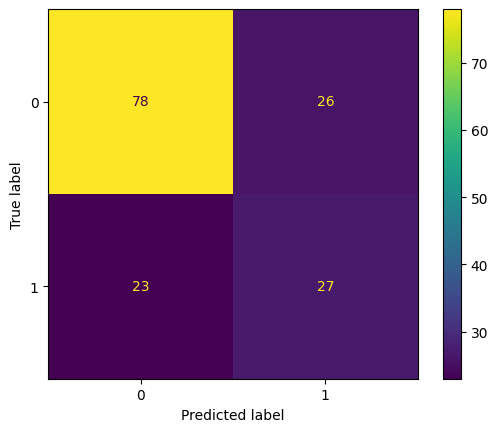

In [17]:
# Let's look at the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

We often predict that someone does not have diabetes even if they do. What can we do to combat this?

### Balance classes

In [20]:
n = pima["label"].value_counts().min()
n

268

In [21]:
# Let's balance our classes
pima_balanced = pima.groupby('label').sample(n = n, replace = False)

In [22]:
pima_balanced

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
669,9,154,78,30,100,30.9,0.164,45,0
87,2,100,68,25,71,38.5,0.324,26,0
374,2,122,52,43,158,36.2,0.816,28,0
76,7,62,78,0,0,32.6,0.391,41,0
174,2,75,64,24,55,29.7,0.370,33,0
...,...,...,...,...,...,...,...,...,...
580,0,151,90,46,0,42.1,0.371,21,1
37,9,102,76,37,0,32.9,0.665,46,1
276,7,106,60,24,0,26.5,0.296,29,1
370,3,173,82,48,465,38.4,2.137,25,1


In [23]:
pima_balanced['label'].value_counts( dropna = False)

,count
label,
0,268
1,268


In [24]:
X = pima_balanced.drop('label',axis=1).copy()
y = pima_balanced['label'].copy()

### Cross validation

In [25]:
numLoops = 50
predict_accuracy = np.zeros(numLoops)
predict_f1 = np.zeros(numLoops)
for idx in range(numLoops):
  # Train/test split
  X_train, X_test, y_train, y_test = model_selection.train_test_split(X,y,test_size=0.2)

  # Create model
  logreg = LogisticRegression(max_iter=1000)

  # Fit ( train ) model
  logreg.fit(X_train,y_train)

  # Predict
  y_pred = logreg.predict(X_test)

  # Calculate and record performance metrics
  predict_accuracy[idx] = metrics.accuracy_score(y_test,y_pred)
  predict_f1[idx] = metrics.f1_score(y_test,y_pred)

print(f"Mean Accuracy: {predict_accuracy.mean()*100:.1f}%")
print(f"F1 Score: {predict_f1.mean()*100:.1f}%")

Mean Accuracy: 74.4%
F1 Score: 73.8%


### Confusion matrix

Let's look at the confusion matrix using the last validation run


<Figure size 800x800 with 0 Axes>

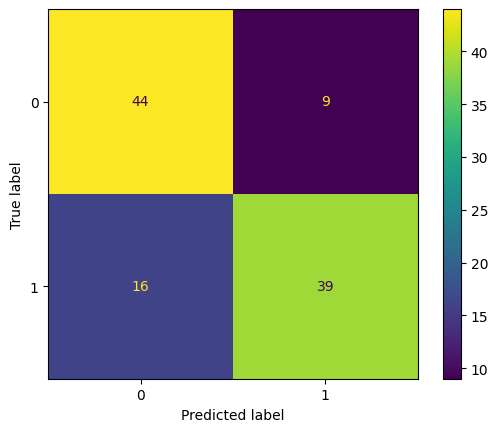

In [26]:
cm = confusion_matrix( y_test, y_pred )
plt.figure(figsize=(8,8))
disp = ConfusionMatrixDisplay( confusion_matrix = cm )
disp.plot()
plt.show()


How does the model make its classifications?

In [27]:
y_pred_proba = logreg.predict_proba(X_test)[:,1]
print(y_pred_proba[0:15]*100)

[ 4.68059975 60.75866363  7.73165976 53.50195233 51.25447092 79.97872218
 15.31157292 40.93158046 90.85143557 57.35831299 96.39924122 82.50130532
 49.7212947  21.70085025 47.75551027]


Pair up preditions with probabilities.  The default threshold is 50%.

In [28]:
sorted( zip( y_pred, y_pred_proba[0:15]*100))


[(np.int64(0), np.float64(4.680599751272592)),
 (np.int64(0), np.float64(7.7316597586637394)),
 (np.int64(0), np.float64(15.31157291513142)),
 (np.int64(0), np.float64(21.700850248469408)),
 (np.int64(0), np.float64(40.931580462998504)),
 (np.int64(0), np.float64(47.7555102673943)),
 (np.int64(0), np.float64(49.72129469507129)),
 (np.int64(1), np.float64(51.25447092475206)),
 (np.int64(1), np.float64(53.50195232799483)),
 (np.int64(1), np.float64(57.35831299495654)),
 (np.int64(1), np.float64(60.75866363153592)),
 (np.int64(1), np.float64(79.97872218437557)),
 (np.int64(1), np.float64(82.50130532292157)),
 (np.int64(1), np.float64(90.8514355665044)),
 (np.int64(1), np.float64(96.39924121514497))]

## ROC-AUC



A receiver operating characteristic ( ROC ) and area under the curve ( AUC ) plot illustrates the performance of a binary classifier model at varying threshold values.  It also enables us to pick an optimal threshold for classification.






### Compute ROC curve and AUC


In [29]:
fpr, tpr, thresholds = roc_curve( y_test, y_pred_proba )
roc_auc = auc(fpr, tpr)


In [30]:
roc_auc

np.float64(0.8545454545454545)

### Plot ROC curve


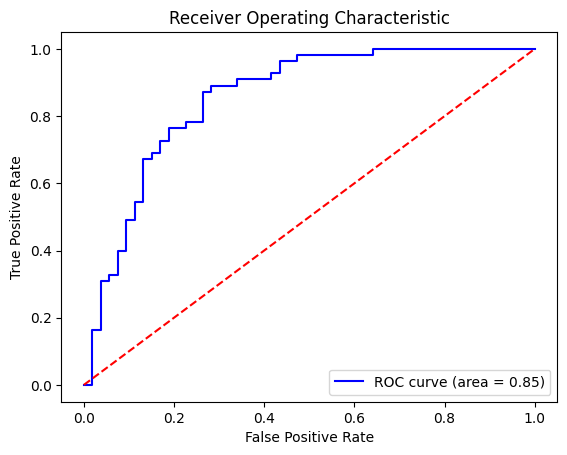

In [31]:
plt.figure()
plt.plot(
  fpr,
  tpr,
  color = 'blue',
  label = f'ROC curve (area = {roc_auc:.2f})',
)
plt.plot(
  [0, 1],
  [0, 1],
  color='red',
  linestyle='--',
)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc='lower right')
plt.show()


In [53]:
np.array([thresholds[:10], fpr[:10], tpr[:10], (tpr - fpr)[:10]]).T

array([[        inf,  0.        ,  0.        ,  0.        ],
       [ 0.96632576,  0.01886792,  0.        , -0.01886792],
       [ 0.92047008,  0.01886792,  0.16363636,  0.14476844],
       [ 0.92015878,  0.03773585,  0.16363636,  0.12590051],
       [ 0.82477169,  0.03773585,  0.30909091,  0.27135506],
       [ 0.81998794,  0.05660377,  0.30909091,  0.25248714],
       [ 0.81082764,  0.05660377,  0.32727273,  0.27066895],
       [ 0.79978722,  0.0754717 ,  0.32727273,  0.25180103],
       [ 0.77208179,  0.0754717 ,  0.4       ,  0.3245283 ],
       [ 0.75408719,  0.09433962,  0.4       ,  0.30566038]])

In [54]:
(tpr - fpr)

array([ 0.        , -0.01886792,  0.14476844,  0.12590051,  0.27135506,
        0.25248714,  0.27066895,  0.25180103,  0.3245283 ,  0.30566038,
        0.39656947,  0.37770154,  0.432247  ,  0.41337907,  0.5406518 ,
        0.52178388,  0.53996569,  0.52109777,  0.55746141,  0.53859348,
        0.57495712,  0.53722127,  0.55540309,  0.51766724,  0.60857633,
        0.5897084 ,  0.60789022,  0.55128645,  0.56946827,  0.49399657,
        0.51217839,  0.49331046,  0.5296741 ,  0.49193825,  0.51012007,
        0.34030875,  0.35849057,  0.        ])

In [70]:
idx = (tpr - fpr).argmax()
idx


np.int64(24)

In [71]:
(tpr - fpr)[idx]

np.float64(0.6085763293310462)

In [73]:
# Find the optimal threshold
optimal_idx = np.argmax(tpr - fpr)  # Point closest to top-left corner
optimal_threshold = thresholds[optimal_idx]

print(f'Optimal threshold: {optimal_threshold}')


Optimal threshold: 0.3911186880476876


### Calculate predictions using ROC-AUC threshold


In [82]:
y_pred = ( y_pred_proba >= optimal_threshold ).astype(int)
#y_pred = ( y_pred_proba >= 0.15 ).astype(int)

y_pred

array([0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1,
       1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1])

### Confusion matrix

<Figure size 800x800 with 0 Axes>

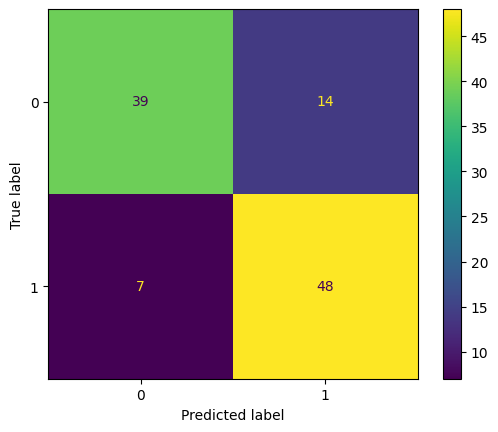

In [83]:
# Let's look at the confusion matrix
cm = confusion_matrix( y_test, y_pred )
plt.figure(figsize=(8,8))
disp = ConfusionMatrixDisplay( confusion_matrix = cm )
disp.plot()
plt.show() ;


### Calculate performance metrics

In [84]:
predict_accuracy = metrics.accuracy_score( y_test, y_pred )
predict_f1 = metrics.f1_score( y_test, y_pred )

print(f"Mean Accuracy: {predict_accuracy*100:.1f}%")
print(f"F1 Score: {predict_f1*100:.1f}%")

Mean Accuracy: 80.6%
F1 Score: 82.1%


## References

- [ROC-AUC]( https://en.wikipedia.org/wiki/Receiver_operating_characteristic )